# Módulo 6 — Decomposição de séries temporais

## Seção 4 — MSTL: decomposição de múltiplas sazonalidades

**Estado:** capítulo didático para revisão. **Pré-requisitos:** Seções 1–3 do Módulo 6, mínimos quadrados e LOESS, noções de frequência sazonal, autocorrelação e uso básico de Pandas. **Notação:** $s_j$ é o período da $j$-ésima sazonalidade; $K$ é o número de sazonalidades; $T_t$ é tendência, $S_{j,t}$ são componentes sazonais e $R_t$ é restante.

**Controle de fundamentação.** O `PLANO_MODULOS_PRIORITARIOS.md` prevê explicitamente MSTL e diagnóstico de resíduos no Módulo 6. O `mapeamento-conteudos-series-temporais.md`, *Aula 2 — Parte II — Decomposição STL e MSTL*, situa múltiplos ciclos sazonais no acervo pedagógico. As fórmulas iterativas e experimentos deste capítulo são **complementação matemática e computacional original**, apoiada na documentação e no código **localmente inspecionado** de `statsmodels.tsa.seasonal.MSTL`, versão 0.14.6. O livro acadêmico principal fundamenta decomposição e suavização clássicas, **não** é citado como se apresentasse o algoritmo MSTL.

### Objetivos

Distinguir uma de várias sazonalidades; formular a decomposição aditiva com $K$ períodos; explicar a confusão entre componentes em um ajuste isolado; desenvolver uma iteração de atualização sazonal por retirada dos demais componentes; usar MSTL em dados horários; confrontar desempenho residual e risco de sobreajuste; reconhecer hipóteses de regularidade temporal e limitações em previsão.

### 1. Motivação: mais de um relógio no mesmo conjunto de dados

Considere consumo de eletricidade coletado **a cada hora**. Pode haver ao menos dois ciclos:

- **Diário:** horário de trabalho, almoço, madrugada — $s_1=24$ observações.
- **Semanal:** dias úteis e finais de semana — $s_2=7\cdot24=168$ observações.

Esses números só fazem sentido se a frequência realmente for **uma observação por hora**. Uma série com dados faltantes e horários irregulares requer calendário adequado antes de escolher períodos numéricos. Também podem existir múltiplos ciclos com durações não inteiras em número de amostras; nesse caso, MSTL com períodos inteiros exige aproximações ou outra abordagem.

No STL convencional, escolhemos um período principal. Ajustar `period=24` não entrega automaticamente uma componente semanal separada. **MSTL** (*Multiple Seasonal-Trend decomposition using LOESS*) estende a decomposição com várias componentes sazonais estimadas por ajustes STL sucessivos e iterativos.

### 2. Definição do modelo aditivo multi-sazonal

Para $K$ sazonalidades, escrevemos

$$
\boxed{y_t=T_t+\sum_{j=1}^{K}S_{j,t}+R_t.}
$$

Se $K=2$, $s_1=24$ e $s_2=168$,

$$
\boxed{y_t=T_t+S_{24,t}+S_{168,t}+R_t.}
$$

Isso não significa que $S_{24,t}$ tenha valores exatamente repetidos todo dia: o método admite mudanças lentas na forma e na amplitude. Tampouco exige que os efeitos diário e semanal sejam probabilisticamente independentes. Os componentes são **estimativas convencionadas**, e sazonalidades sobrepostas podem dificultar a separação única.

**Exemplo numérico simples.** Em um instante, suponha $y_t=31$, tendência $T_t=30$, componente diário $S_{24,t}=3$ e semanal $S_{168,t}=-1$. Então, pela identidade,

$$
R_t=31-30-3-(-1)=-1.
$$

A aritmética confirma a reconstrução, mas **não** indica como foram estimados $T_t$, $S_{24,t}$ ou $S_{168,t}$. Para isso precisamos do algoritmo.

### 3. Por que não estimar cada sazonalidade isoladamente?

Suponha que o processo observado seja

$$
y_t=T_t+S_{1,t}+S_{2,t}+R_t.
$$

Se executamos uma rotina de extração do primeiro ciclo diretamente sobre $y_t$, ela recebe também $S_{2,t}$, $T_t$ e $R_t$. Parte do segundo ciclo pode contaminar o primeiro ajuste, principalmente se existirem frequências próximas, múltiplas relações harmônicas ou poucos ciclos completos. O problema é de **atribuição**: qual parcela das oscilações pertence a qual componente?

A estratégia iterativa consiste em retirar as estimativas correntes dos **outros** ciclos antes de atualizar uma sazonalidade. Isso se aproxima conceitualmente de uma atualização por blocos: cada componente é reestimado enquanto os demais são mantidos fixos.

### 4. Derivação operacional das atualizações

Considere $K$ períodos $(s_1,\ldots,s_K)$ e estimativas correntes $S_{j,t}^{(k)}$. Para atualizar a sazonalidade de índice $j$, construa a série parcial

$$
\boxed{y_{t}^{[-j]}=y_t-\sum_{\ell\ne j}S_{\ell,t}^{(k/\,k+1)}.}
$$

O sobrescrito $(k/\,k+1)$ indica que, numa passagem sequencial, algumas sazonalidades já foram atualizadas e outras ainda conservam valores da iteração anterior. Aplique STL com período $s_j$ à série parcial:

$$
\bigl(\widetilde T_{j,t},\widetilde S_{j,t},\widetilde R_{j,t}\bigr)
=\operatorname{STL}_{s_j}(y_t^{[-j]}).
$$

Então atualize

$$
\boxed{S_{j,t}^{(k+1)}\leftarrow\widetilde S_{j,t}.}
$$

Após percorrer todos os períodos e concluir o número de passagens escolhido, estime a tendência final e defina

$$
\boxed{R_t=y_t-\widehat T_t-\sum_{j=1}^K\widehat S_{j,t}.}
$$

Essa representação corresponde à lógica operacional examinada no `MSTL.fit()` instalado: a rotina reinclui a sazonalidade corrente, ajusta um STL com o respectivo período, subtrai a nova sazonalidade e avança. **Detalhe de implementação:** no `statsmodels` 0.14.6, a tendência final é a tendência devolvida pelo último ajuste STL da última passagem; portanto não descrevemos uma suavização global separada que não foi verificada no código.

### 5. Um microexemplo para visualizar a retirada de componentes

Suponha que, em um dado instante, $y_t=41$. A estimativa corrente de tendência é aproximadamente 35, e a sazonalidade semanal estimada vale $-2$. Ao estimar a sazonalidade diária, a entrada parcial é

$$
y_t^{[-24]}=41-(-2)=43.
$$

Agora a rotina STL diária encontra uma sazonalidade diária provisória, por exemplo $4$, juntamente com tendência e restante. **O número 4 é apenas ilustrativo**, não resultado deduzido a partir de um único instante. Depois, para atualizar a sazonalidade semanal com a sazonalidade diária atualizada igual a 4,

$$
y_t^{[-168]}=41-4=37.
$$

O exemplo mostra o significado do *vai e volta* da atualização, mas uma janela temporal de vários ciclos é indispensável para que as suavizações identifiquem qualquer forma sazonal.

### 6. Pseudocódigo antes do Python

```text
entrada: serie regular y, periodos s[1..K], janelas de suavizacao, N_iter
inicializar todas as componentes sazonais com zero
repetir N_iter vezes:
    para j = 1..K:
        serie_parcial = y - soma das outras componentes sazonais atuais
        (tendencia_local, sazonalidade_j, residuo_local) = STL(serie_parcial, periodo=s[j])
        atualizar componente sazonal j
usar tendencia do ultimo ajuste STL
residuo_final = y - tendencia - soma das componentes sazonais
saida: tendencia, K sazonalidades, residuo
```

A descrição é uma forma didática do algoritmo sequencial para dados completos. O código real também trata índices, formatos de saída, escolhas de janela, transformação Box–Cox opcional e casos especiais.

### 7. Por que múltiplas sazonalidades exigem cuidados de identificação?

**Periodicidades relacionadas.** A semana tem exatamente sete ciclos diários. Isso significa que certas formas periódicas de 24 horas também são periódicas em 168 horas. As duas bases podem representar oscilações coincidentes; **a separação entre $S_{24,t}$ e $S_{168,t}$ não é única sem escolhas de suavização e identificação**. O método impõe uma separação operacional por janelas e ordem de estimação, não prova que os mecanismos físicos foram recuperados.

**Amplitude mutável.** Janelas sazonais curtas respondem rapidamente, mas podem absorver ruído. Janelas longas produzem componentes mais estáveis, porém podem atrasar a identificação de mudanças.

**Comprimento amostral.** Para estimar um ciclo semanal com dados horários, poucas semanas fornecem pouquíssimas observações por posição semanal. A estabilidade da extração depende de quantidade de ciclos, ruído, lacunas e parametrização.

**Escala.** Na série positiva, o logaritmo transforma um modelo multiplicativo $y_t=T_t\prod_jS_{j,t}I_t$ em uma decomposição aditiva **desde que todos os componentes e observações sejam positivos**. Com zeros reais ou negativos, não faça log automaticamente. A reversão das componentes e das previsões exige cuidado com viés, como no Módulo 5.

### 8. Implementação em Python: comparação entre STL e MSTL

**Ambiente:** Python 3, `numpy`, `pandas`, `matplotlib` e `statsmodels>=0.14` (versão utilizada: 0.14.6). `MSTL` recebe `periods=(24,168)` para duas sazonalidades; `windows=(13,15)` configura suavizações sazonais de cada período. `iterate=2` solicita duas passagens pelas sazonalidades; não significa dois ciclos observados.

In [ ]:
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import STL, MSTL

rng = np.random.default_rng(321019)
n = 24*56  # 56 dias de dados horarios, oito ciclos semanais
t = np.arange(n)
T = 30 + 0.0018*t + np.sin(2*np.pi*t/(24*35))
S24 = (2.2*np.sin(2*np.pi*t/24) + 0.6*np.cos(4*np.pi*t/24))*(1+0.00025*t)
S168 = 1.6*np.cos(2*np.pi*t/168+0.3) + 0.35*np.sin(4*np.pi*t/168)
ruido = rng.normal(0, 0.32, n)
serie = pd.Series(T + S24 + S168 + ruido,
                 index=pd.date_range('2025-01-01', periods=n, freq='h'))

stl_diario = STL(serie, period=24, seasonal=13, trend=49).fit()
multiplas = MSTL(serie, periods=(24,168), windows=(13,15),
                 iterate=2, stl_kwargs={'robust': False}).fit()

print(multiplas.seasonal.columns.tolist())
# ['seasonal_24', 'seasonal_168']
reconstruida = multiplas.trend + multiplas.seasonal.sum(axis=1) + multiplas.resid
assert np.allclose(reconstruida, serie)

# Uma ACF simples com denominador comum n, nas defasagens desejadas.
def acf_amostral_lag(x, h):
    x = np.asarray(x, dtype=float)
    d = x - x.mean()
    return np.dot(d[:-h], d[h:]) / np.dot(d, d)

for lag in (24, 168):
    print(f'lag={lag}: STL={acf_amostral_lag(stl_diario.resid,lag):+.3f}; '
          f'MSTL={acf_amostral_lag(multiplas.resid,lag):+.3f}')

`np.arange` cria um índice de passos temporais; `pd.date_range(freq='h')` dá a eles significado físico de horas regulares; `MSTL.fit()` retorna tendência, uma tabela com duas colunas sazonais e resíduos; `DataFrame.sum(axis=1)` soma as sazonalidades de um mesmo instante; `np.allclose` verifica a **reconstrução algébrica**.

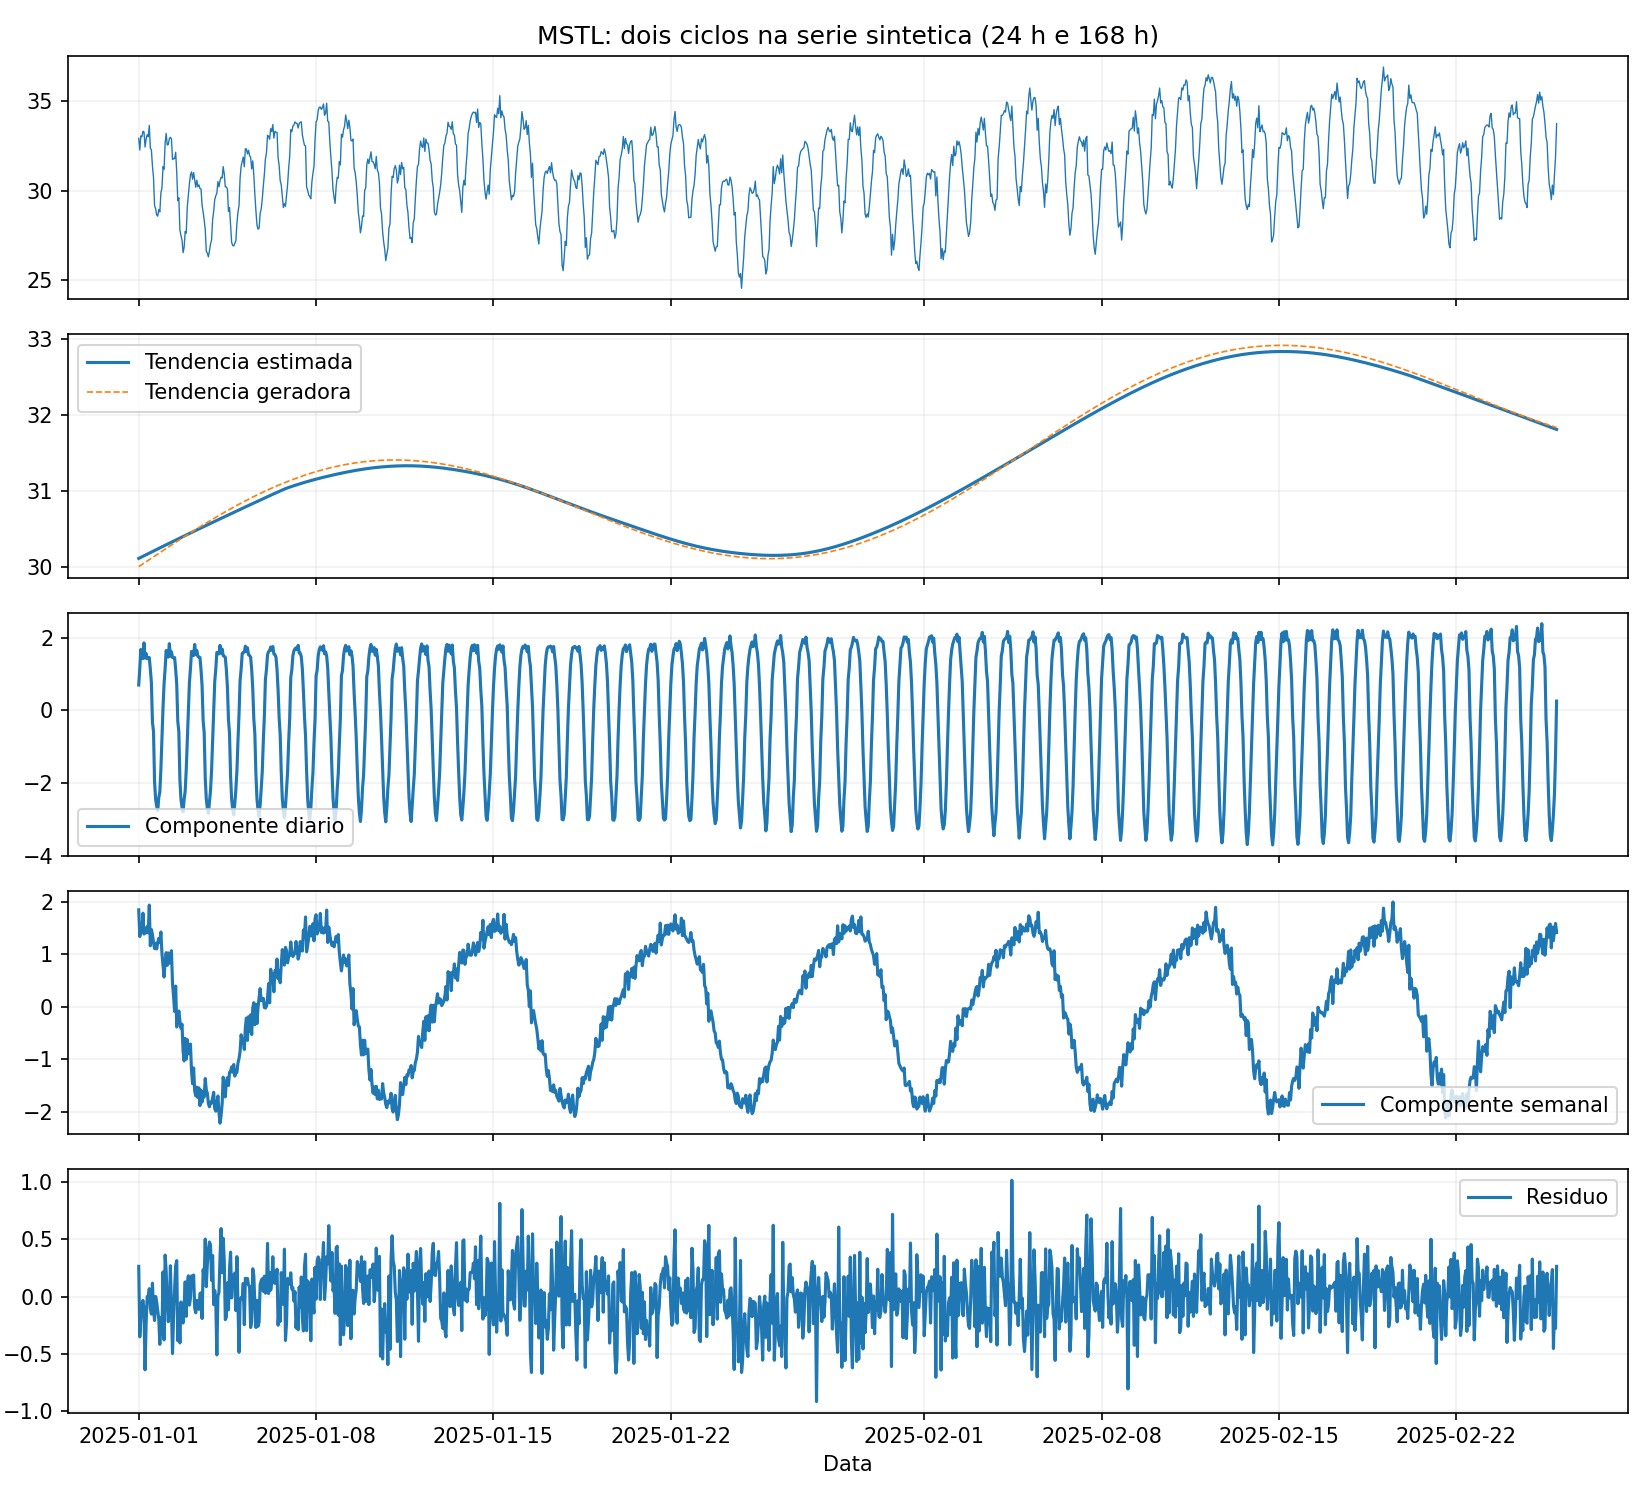

*Figura 4.1 — Série sintética horária com sazonalidades geradoras de 24 e 168 horas. MSTL devolve componentes sazonais separados, uma tendência e um resíduo. As curvas estimadas não são necessariamente idênticas aos componentes geradores.*

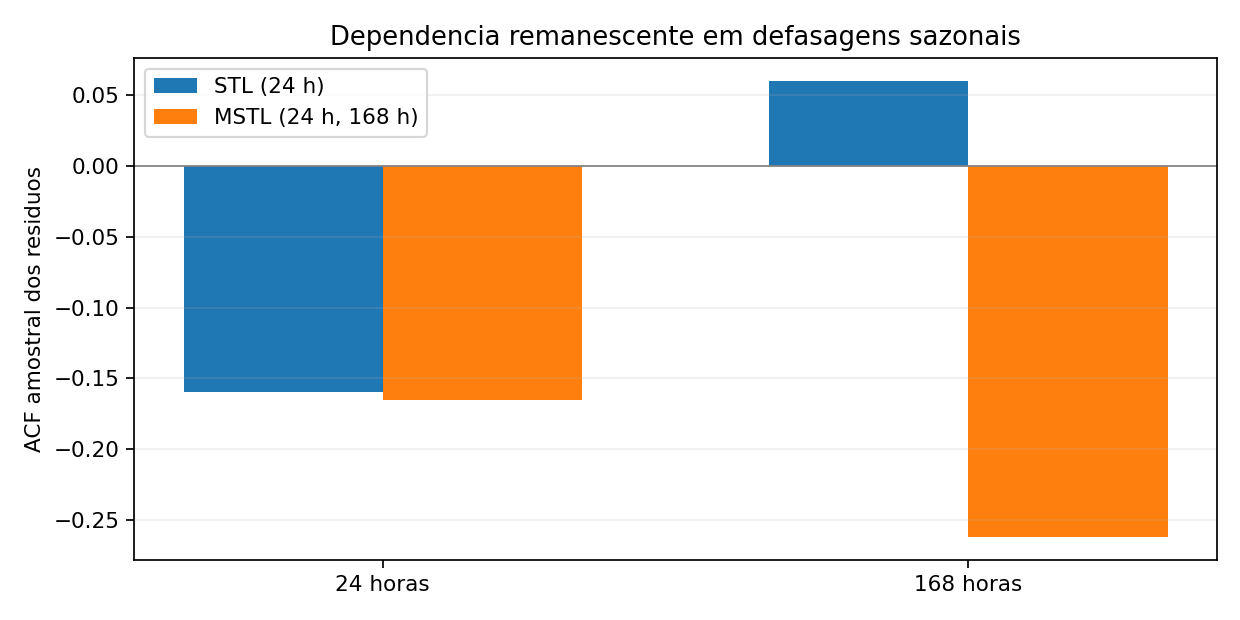

*Figura 4.2 — Autocorrelação amostral residual nas defasagens 24 e 168, para STL com período 24 e MSTL com períodos 24 e 168. **Neste experimento**, o valor de ACF em 168 horas foi cerca de $0{,}060$ para STL e $-0{,}262$ para MSTL; a magnitude cresceu no segundo caso. Logo, não se deve interpretar a mera presença de mais componentes como melhoria automática no diagnóstico de resíduos.*

### 9. Como interpretar esse resultado sem exagerar?

O objetivo imediato do MSTL é **descrever mais de uma sazonalidade**; isso é diferente de maximizar o ajuste a inovações conhecidas ou produzir resíduos sem dependência. O experimento contém oito ciclos semanais, e a extração de uma sazonalidade semanal variável pode ficar instável. Além disso, a periodicidade de 168 horas contém harmônicas da periodicidade de 24 horas. Essas características exigem cuidado com janelas e identificação.

As métricas residuais isoladas não são provas de superioridade. Nesta simulação, como conhecemos o ruído verdadeiro, também poderíamos comparar $\widehat R_t$ com esse ruído, mas em dados reais ele é desconhecido. A **validação preditiva cronológica** e o diagnóstico das componentes continuam necessários.

### 10. Restrições práticas e riscos de vazamento temporal

1. **STL e MSTL são geralmente retrospectivos:** suavizações locais podem utilizar observações posteriores ao instante que estão estimando. Não decomponha o conjunto completo antes de definir treino e teste, se a decomposição influenciar a previsão.
2. **`periods` não são durações abstratas:** representam contagens de observações. Dados agregados diariamente teriam período semanal 7, não 168.
3. **Dados ausentes:** a biblioteca pode não interpretar ausências como você espera; diferencie valor faltante de zero genuíno e defina tratamento explícito.
4. **Múltiplos ciclos e frequências harmônicas:** componentes podem ficar confundidos; não reivindique identificabilidade física sem hipóteses adicionais.
5. **Proximidade de mudanças estruturais:** robustez e LOESS não substituem um modelo de quebra, intervenção ou mudança de regime quando isso for a hipótese científica.
6. **Heterocedasticidade:** múltiplas sazonalidades não corrigem automaticamente variância variável. Escolher log/Box–Cox deve respeitar o suporte e, em validação, usar apenas treino.
7. **Resíduos:** autocorrelações pequenas em algumas defasagens não provam ruído branco; autocorrelações grandes não estabelecem, sozinhas, qual sazonalidade está mal especificada.

### 11. Exercícios orientados

1. **Conceitual:** explique por que $s=24$ e $s=168$ são períodos coerentes para dados horários e incoerentes para dados diários, sem reinterpretação.
2. **Cálculo:** com $y_t=54$, $T_t=50$, $S_{24,t}=5$ e $S_{168,t}=-3$, calcule $R_t$ e verifique a reconstrução.
3. **Pseudocódigo:** desenhe duas iterações de atualização sequencial para $K=2$; indique em qual momento se subtrai cada componente.
4. **Identificação:** demonstre que uma função determinística de período 24 também possui período 168. Explique como isso dificulta separar componentes no caso de dados horários.
5. **Código:** altere `windows=(13,15)` para `(19,21)` mantendo o mesmo gerador. Compare os componentes estimados e os resíduos sem assumir qual opção será melhor.
6. **Avaliação:** proponha um protocolo de validação em origem móvel para estimar componentes sem observar o futuro.
7. **Pesquisa:** se uma série apresenta valores zero em parte do dia, por que transformar todos os valores por logaritmo seria inadequado? Discuta alternativas e os riscos de adicionar constante arbitrária.

**Conferências selecionadas:** exercício 2: $R_t=54-50-5-(-3)=2$. Exercício 4: se $f(t+24)=f(t)$, então $f(t+168)=f(t+7\cdot24)=f(t)$ pela aplicação repetida da identidade.

### 12. Síntese e referências

MSTL estima sazonalidades múltiplas por **passagens iterativas de STL**, subtraindo as demais sazonalidades antes de atualizar cada componente. É especialmente útil quando a amostragem é regular e existem vários ciclos substantivamente justificáveis. Entretanto, a decomposição não é única em geral, e mais componentes não asseguram resíduos melhores, muito menos desempenho preditivo superior.

- MORETTIN, P. A.; TOLOI, C. M. C. *Análise de séries temporais: modelos lineares univariados*. 3. ed., v. 1. Blucher, 2018. Cap. 3, §§3.2–3.3. **Base geral para tendência/sazonalidade/decomposição; não é fonte atribuída para a recursão MSTL.**
- `PLANO_MODULOS_PRIORITARIOS.md`, Módulo 6, e `mapeamento-conteudos-series-temporais.md`, *Aula 2 — Parte II*. **Fontes de planejamento e cobertura pedagógica.**
- BANDARA, K.; HYNDMAN, R. J.; BERGMEIR, C. *MSTL: A Seasonal-Trend Decomposition Algorithm for Time Series with Multiple Seasonal Patterns*, 2021. **Referência temática para aprofundamento; artigo não consultado diretamente nesta elaboração.**
- Implementação `statsmodels.tsa.seasonal.MSTL.fit`, versão 0.14.6: **código instalado inspecionado diretamente** para confirmar a sequência de atualizações; exemplos sintéticos e discussões de identificação são complementações deste material.